# Merge and Visualise Data

In [ ]:
import numpy as np
import joblib
from collections import Counter

def visualise_data(filename):
	# Load the dataset
	data = np.load(filename, allow_pickle=True)

	# Check total samples
	print(f"Total samples collected: {len(data)}")

	# Extract actions from (state, action) pairs
	states, actions = zip(*data)
	states = np.array(states)
	actions = np.array(actions)

	# Count occurrences of each action
	action_counts = Counter(actions)
	print(f"Action distribution: {action_counts}")


def merge_datasets(filenames, filename="training_data.npy"):
	# Load the datasets
	datasets = [np.load(filename, allow_pickle=True) for filename in filenames]

	# Merge the datasets
	merged_dataset = np.concatenate(datasets)

	# Remove the first value from each state
	# modified_dataset = [(state[2:], action) for state, action in merged_dataset]

	modified_dataset = []
	for state, action in merged_dataset:
		self_distance_to_goal = state[2]

		if state[6] != 0:
			state[6] = 1 if state[6] < self_distance_to_goal else 0
		
		if state[10] != 0:
			state[10] = 1 if state[10] < self_distance_to_goal else 0

	# Shuffle to mix samples
	np.random.shuffle(modified_dataset)

	# Save the merged dataset
	np.save(filename, np.array(modified_dataset, dtype=object))
	print(f"Saved merged dataset to {filename}")


merge_datasets(["raw_training_data_1.npy", "raw_training_data_2.npy"])
visualise_data("training_data.npy")

Saved merged dataset to training_data.npy
Total samples collected: 120069
Action distribution: Counter({0: 67174, 1: 52895})


# Standardisation

In [2]:
from sklearn.preprocessing import StandardScaler

# Extract states (features) and actions
data = np.load("training_data.npy", allow_pickle=True)
states, actions = zip(*data)
states = np.array(states)

# Apply Standardisation
scaler = StandardScaler()
scaled_states = scaler.fit_transform(states)

# Save standardized dataset
standardized_data = list(zip(scaled_states, actions))
np.save("standardised_data/standardised_training_data.npy", np.array(standardized_data, dtype=object))
print("Standardised data successfully saved!")

# Save the scaler for inference
joblib.dump(scaler, "standardised_data/standard_scaler.pkl")
print("Standard Scaler saved!")

Standardised data successfully saved!
Standard Scaler saved!


# Min-Max Normalisation

In [3]:
from sklearn.preprocessing import MinMaxScaler

# Extract states (features) and actions
data = np.load("training_data.npy", allow_pickle=True)
states, actions = zip(*data)
states = np.array(states)

# Apply Min-Max Scaling
scaler = MinMaxScaler()
scaled_states = scaler.fit_transform(states)

# Save normalized dataset
normalized_data = list(zip(scaled_states, actions))
np.save("minmax_data/minmax_training_data.npy", np.array(normalized_data, dtype=object))
print("Min-Max normalised data successfully saved!")

# Save the scaler for inference
joblib.dump(scaler, "minmax_data/minmax_scaler.pkl")
print("Min-Max Scaler saved!")

Min-Max normalised data successfully saved!
Min-Max Scaler saved!


# Logisitic Regression

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

def logistic_regression(data_path):
    # Load dataset
    data = np.load(data_path, allow_pickle=True)
    states, actions = zip(*data)
    states = np.array(states)
    actions = np.array(actions)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
		states, actions, test_size=0.2, random_state=42
	)

    # Train Logistic Regression
    model = LogisticRegression()
    model.fit(X_train, y_train)

    # Evaluate
    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    print(f"Logistic Regression Accuracy for {data_path}: {accuracy * 100:.2f}%")
    print(cm)

    joblib.dump(model, "linear_regression_model.pkl")

# Test on standardised data
logistic_regression("standardised_data/standardised_training_data.npy")

# Test on min-max normalised data
# logistic_regression("minmax_data/minmax_training_data.npy")

Logistic Regression Accuracy for standardised_data/standardised_training_data.npy: 74.69%
[[10312  3108]
 [ 2969  7625]]


# Decision Tree

In [5]:
from sklearn.tree import DecisionTreeClassifier

def decision_tree(data_path):
	# Load dataset
	data = np.load(data_path, allow_pickle=True)
	states, actions = zip(*data)
	states = np.array(states)
	actions = np.array(actions)

	# Split dataset
	X_train, X_test, y_train, y_test = train_test_split(
		states, actions, test_size=0.2, random_state=42
	)

	# Train Decision Tree
	tree = DecisionTreeClassifier(max_depth=5)  # Limit depth to prevent overfitting
	tree.fit(X_train, y_train)

	# Evaluate
	y_pred = tree.predict(X_test)
	accuracy = accuracy_score(y_test, y_pred)
	print(f"Decision Tree Accuracy for {data_path}: {accuracy * 100:.2f}%")
    
	joblib.dump(tree, "decision_tree_model.pkl")

	return tree

# Test on standardised data
tree = decision_tree("standardised_data/standardised_training_data.npy")

# Test on min-max normalised data
# tree = decision_tree("minmax_data/minmax_training_data.npy")

Decision Tree Accuracy for standardised_data/standardised_training_data.npy: 76.14%


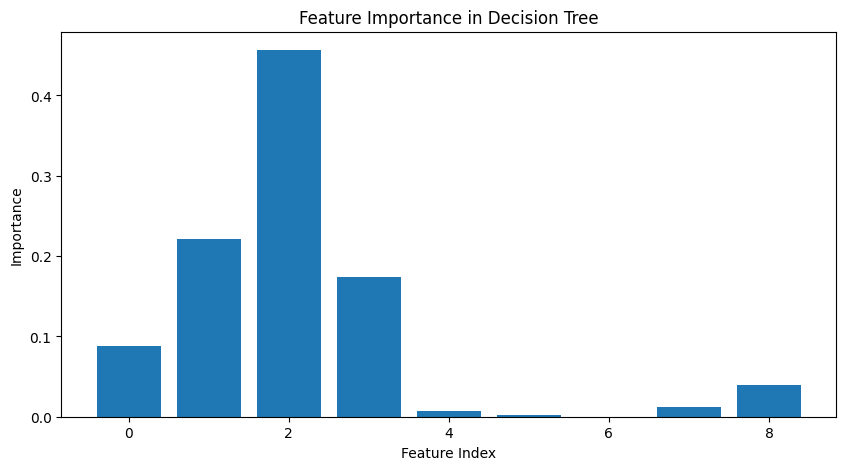

In [6]:
import matplotlib.pyplot as plt

# Get feature importance from Decision Tree
importance = tree.feature_importances_

# Plot
plt.figure(figsize=(10, 5))
plt.bar(range(len(importance)), importance)
plt.xlabel("Feature Index")
plt.ylabel("Importance")
plt.title("Feature Importance in Decision Tree")
plt.show()

# Random Forest

In [7]:
from sklearn.ensemble import RandomForestClassifier

def random_forest(data_path):
    # Load dataset
    data = np.load(data_path, allow_pickle=True)
    states, actions = zip(*data)
    states = np.array(states)
    actions = np.array(actions)

    # Split dataset
    X_train, X_test, y_train, y_test = train_test_split(
		states, actions, test_size=0.2, random_state=42
	)

    # Train Random Forest
    forest = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
    forest.fit(X_train, y_train)

    # Evaluate
    y_pred = forest.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    print(f"Random Forest Accuracy for {data_path}: {accuracy * 100:.2f}%")
    joblib.dump(forest, "random_forest_model.pkl")


# Test on standardised data
random_forest("standardised_data/standardised_training_data.npy")

# Test on min-max normalised data
# random_forest("minmax_data/minmax_training_data.npy")

Random Forest Accuracy for standardised_data/standardised_training_data.npy: 90.40%
